# Python for Analytics Assignment
### **_Revenue Growth & Business Strategy from Sales Data_** 
| Members Name (Group 5) | Roll No. |
|---|---|
| Arhant Doongarwal | 005 |
| Hriman Saha | 011 |
| Lakshita Purvar | 016 |
| Ravi Pratap Singh | 022 |
| Shreyit Sinha | 027 |
| Wali Abidi | 032 |
---

**Objective - "How can the business grow revenue over the next 12 months, and which specific actions should leadership prioritise?"**

---
## Table of Contents

<details>
<summary><b>1. Data Cleaning & Preprocessing</b></summary>

- [1.1 Load Raw Data](#load-raw-data)
- [1.2 Data Audit](#data-audit)
- [1.3 Descriptive Statistics](#descriptive-statistics)
- [1.4 Rename Columns](#rename-columns)
- [1.5 Extract Date Features](#extract-date-features)
- [1.6 Duplicate Analysis](#duplicate-analysis)
- [1.7 Aggregate Duplicates](#aggregate-duplicates)
- [1.8 Remove Invalid Rows](#remove-invalid-rows)
- [1.9 Revenue Bands](#added-revenue-bands)

</details>

<details>
<summary><b>2. Exploratory Data Analysis</b></summary>

- [2.1 Regional OLS](#regional-ols)
- [2.2 Revenue Trend by Fiscal Year](#revenue-trend)
- [2.3 YoY Seasonality](#yoy-seasonality)

</details>

<details>
<summary><b>3. Deep Dive Analyses</b></summary>

- [3.1 BCG Matrix — Division Performance](#bcg-matrix)
- [3.2 Customer Pareto](#customer-pareto)
- [3.3 Top 10 Customers](#top10-customers)
- [3.4 Customer Churn](#customer-churn)
- [3.5 AOV Trend by Product Class](#aov-trend)
- [3.6 Product Mix Evolution](#product-mix)
- [3.7 Cross-sell Gap](#cross-sell-gap)
- [3.8 SKU Pareto](#sku-pareto)
- [3.9 Top 10 SKUs](#top10-skus)

</details>

<details>
<summary><b>4. Advanced Analytics</b></summary>

- [4.1 End-market × Division Heatmap](#endmarket-heatmap)
- [4.2 YoY Revenue Waterfall](#yoy-waterfall)
- [4.3 Customer Segmentation](#customer-clustering)
- [4.4 Division Co-purchase Analysis](#basket-analysis)

</details>

<details>
<summary><b>5. Strategic Recommendations</b></summary>

- [5.1 Recommendations](#recommendations)

</details>

<details>
<summary><b>6. Revenue Projection</b></summary>

- [6.1 Projected Revenue with Levers](#revenue-projection)

</details>

<details>
<summary><b>7. AI Declaration & References</b></summary>

- [7.1 AI Declaration & References](#ai-declaration)

</details>

---

*Click on any section to expand/collapse*

---

#### Stage 1: Data Cleaning and Preprocessing

**Dataset:** 4-year retail order data (2023 to 2026)
**Goal:** Clean the raw data for downstream analysis

In [419]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
    
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

### <a id='load-raw-data'></a>1.1 Load Raw Data

In [420]:
df_raw = pd.read_parquet("../data/final_student_dataset.parquet")
df_raw.shape, list(df_raw.columns)

((2421385, 16),
 ['order number',
  'product_class',
  'cdm duns name',
  'cdm parent duns name',
  'amount p$',
  'cdm end market',
  'division',
  'order create date',
  'fiscal year',
  'hfm region',
  'hfm region group',
  'sku name',
  'sku number',
  'quantity',
  'ship to number',
  'ship to name'])

### <a id='data-audit'></a>1.2 Data Audit

In [421]:
null_df = pd.DataFrame({
    "null_count": df_raw.isnull().sum(),
    "null_pct_%": (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
null_df

print(f"Fully duplicate rows: {df_raw.duplicated().sum()}")
print(f"Duplicate (order + sku) pairs: {df_raw.duplicated(subset=['order number','sku number']).sum()}")

Fully duplicate rows: 242223
Duplicate (order + sku) pairs: 414351


### <a id='descriptive-statistics'></a>1.3 Descriptive Statistics

In [422]:
df_raw["amount p$"] = pd.to_numeric(df_raw["amount p$"], errors="coerce")
df_raw["quantity"] = pd.to_numeric(df_raw["quantity"], errors="coerce")

df_raw[["amount p$", "quantity"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2)

,amount p$,quantity
count,"2,421,385.00","2,421,385.00"
mean,"3,056.59",20.33
std,"86,246.95","1,040.99"
min,0.00,"-1,000.00"
1%,1.00,1.00
5%,5.00,1.00
25%,62.00,1.00
50%,216.00,1.00
75%,702.00,5.00
95%,"6,342.00",36.00


In [423]:
df_raw[df_raw["amount p$"] == 0].shape[0] # $0 revenue rows

22373

In [424]:
df_raw[df_raw["quantity"] < 0].shape[0] # negative quantity rows

173

**Categorical Distributions**

In [425]:
category_cols = [
    'product_class', 'cdm duns name', 'cdm parent duns name',
    'cdm end market', 'division', 'hfm region', 'hfm region group',
    'sku name'
]
for col in category_cols:
    df_raw[col] = df_raw[col].astype('category')

df_raw.dtypes

order number                    object
product_class                 category
cdm duns name                 category
cdm parent duns name          category
amount p$                      float64
cdm end market                category
division                      category
order create date       datetime64[us]
fiscal year                      int32
hfm region                    category
hfm region group              category
sku name                      category
sku number                      object
quantity                       float64
ship to number                  object
ship to name                    object
dtype: object

In [426]:
df_raw.nunique()

order number            844786
product_class                2
cdm duns name            30906
cdm parent duns name     22860
amount p$                43658
cdm end market              12
division                    24
order create date         1210
fiscal year                  4
hfm region                  16
hfm region group             8
sku name                146651
sku number              155758
quantity                  3078
ship to number           61108
ship to name             41647
dtype: int64

**Date Range Check**

- Date range: 2023-01-01 to 2026-04-24
- Fiscal years: 2023, 2024, 2025, 2026
- Fiscal year starts October

In [427]:
print(f"Date range: {df_raw['order create date'].min().date()} to {df_raw['order create date'].max().date()}")
df_raw["fiscal year"].value_counts()

Date range: 2023-01-01 to 2026-04-24


fiscal year
2023    767364
2024    746821
2025    711230
2026    195970
Name: count, dtype: int64

### <a id='rename-columns'></a>1.4 Rename Columns

In [428]:
df = df_raw.copy()
df.columns = df.columns.str.replace(' ', '_')
df.columns = df.columns.str.replace('p$', 'usd')
df.columns

Index(['order_number', 'product_class', 'cdm_duns_name',
       'cdm_parent_duns_name', 'amount_usd', 'cdm_end_market', 'division',
       'order_create_date', 'fiscal_year', 'hfm_region', 'hfm_region_group',
       'sku_name', 'sku_number', 'quantity', 'ship_to_number', 'ship_to_name'],
      dtype='object')

In [429]:
df['cdm_duns_name'].value_counts()

cdm_duns_name
Garcia, White and Thompson       47508
Simpson-Solis                    32143
Salazar, Smith and Spencer       22469
Weber, Delgado and Brown         19986
Edwards-Watkins                  19307
                                 ...  
Bell-Washington                      1
Rojas Group                          1
Rogers-Washington                    1
Kline-Thompson                       1
Johnston, Williams and Nguyen        1
Name: count, Length: 30906, dtype: int64

### <a id='extract-date-features'></a>1.5 Extract Date Features

In [430]:
df["year"] = df["order_create_date"].dt.year
df["month"] = df["order_create_date"].dt.month
df["quarter"] = df["order_create_date"].dt.quarter

df["fiscal_year_derived"] = df["year"] + (df["month"] >= 10).astype(int)
incorrect_fy = (df["fiscal_year"] - df["fiscal_year_derived"]) > 1
incorrect_fy.value_counts()

False    2419637
True        1748
Name: count, dtype: int64

_Correcting the wrong fiscal year_

In [431]:
df["fiscal_year_derived"] = (np.where(df["month"] >= 10, df["year"] + 1, df["year"])).astype(int)
df["fiscal_year_derived"].value_counts().sort_index()

fiscal_year_derived
2023    621666
2024    756373
2025    705085
2026    338261
Name: count, dtype: int64

### <a id='duplicate-analysis'></a>1.6 Duplicate Analysis

In [432]:
dup_mask = df.duplicated(subset=["order_number", "sku_number"], keep=False)
group_sizes = df.groupby(['order_number', 'sku_number']).size()
print(f"Total rows: {len(df):,}")
print(f"Unique order+SKU combinations: {len(group_sizes):,}")
print(f"Rows with duplicates: {dup_mask.sum():,}")
print(f"\nGroup size distribution:")
group_sizes.value_counts()

Total rows: 2,421,385
Unique order+SKU combinations: 2,007,034
Rows with duplicates: 583,251

Group size distribution:


1      1838134
2       118542
3        21276
4         9684
5         3714
        ...   
367          1
132          1
198          1
166          1
389          1
Name: count, Length: 119, dtype: int64

### <a id='aggregate-duplicates'></a>1.7 Aggregate Duplicates

In [433]:
df = df.groupby(
    ["order_number", "sku_number"],
    as_index=False
).agg({
    "amount_usd": "sum",
    "quantity": "sum",
    "sku_name": "first",
    "division": "first",
    "product_class": "first",
    "cdm_end_market": "first",
    "hfm_region": "first",
    "hfm_region_group": "first",
    "ship_to_name": "first",
    "ship_to_number": "first",
    "cdm_duns_name": "first",
    "cdm_parent_duns_name": "first",
    "fiscal_year": "first",
    "fiscal_year_derived": "first",
    "order_create_date": "min"
})

# Re-derive date parts and enforce correct dtypes
df["year"]  = df["order_create_date"].dt.year.astype("Int32")
df["month"] = df["order_create_date"].dt.month.astype("Int32")
df["quarter"] = df["order_create_date"].dt.quarter.astype("Int32")
df["fiscal_year_derived"] = df["fiscal_year_derived"].astype("Int32")

print(f"Rows after aggregation: {len(df):,}")

Rows after aggregation: 2,007,034


In [434]:
df.duplicated().sum()

np.int64(0)

### <a id='remove-invalid-rows'></a>1.8 Remove Invalid Rows

In [435]:
df = df[df["amount_usd"] > 0].reset_index(drop=True)
print(f"Rows after removal: {len(df):,}")

Rows after removal: 1,989,489


**Remove Invalid Quantity Rows**

- Negative quantities are data entry errors.

In [436]:
# Remove fractional/invalid quantities (keep only whole-unit orders)
df = df[df["quantity"] >= 1].reset_index(drop=True)
print(f"Rows after quantity filter (>=1): {len(df):,}")

Rows after quantity filter (>=1): 1,988,535


**Compute Unit Price & Remove Anomalies**

In [437]:
df["unit_price"] = df["amount_usd"] / df["quantity"]

bad_rows = df[(df["unit_price"] < 0.001) & (df["quantity"] > 100000)]
df = df.drop(bad_rows.index).reset_index(drop=True)

print(f"Anomaly rows removed: {len(bad_rows)}")

Anomaly rows removed: 2


**Remove High-Revenue Outliers**

- Orders with amount > $50M are extreme outliers.

In [438]:
rev_threshold = 50000000
df["high_revenue_flag"] = (df["amount_usd"] > rev_threshold)
display(df[df["high_revenue_flag"] == True][["order_number", "sku_name", 'quantity', "amount_usd"]])

df = df[~df["high_revenue_flag"]].reset_index(drop=True)

,order_number,sku_name,quantity,amount_usd
1235463,753351,Concern Fire Kit,1.00,"112,340,132.00"


In [439]:
df.shape

(1988532, 22)

### <a id='added-revenue-bands'></a>1.9 Revenue Bands

In [440]:
df["revenue_band"] = pd.cut(
    df["amount_usd"],
    bins=[0, 100, 500, 2000, 10000, float("inf")],
    labels=["<$100", "$100-500", "$500-2K", "$2K-10K", "$10K+"]
)
df["revenue_band"].value_counts().sort_index()

revenue_band
<$100       571594
$100-500    732672
$500-2K     418828
$2K-10K     188751
$10K+        76687
Name: count, dtype: int64

In [441]:
df.shape

(1988532, 23)

**Data Reduction Summary**

| Stage | Rows Changed | Total |
|:---|---:|---:|
| Raw | - | 2,421,385 |
| Aggregate duplicates | -414,351 | 2,007,034 |
| Remove zero revenue | -17,545 | 1,989,489 |
| Remove invalid qty | -954 | 1,988,535 |
| Remove anomalies | -2 | 1,988,533 |
| Remove outlier | -1 | 1,988,532 |

In [442]:
df.to_parquet("cleaned_dataset.parquet", index=False)

In [443]:
df.describe()

,amount_usd,quantity,fiscal_year,fiscal_year_derived,order_create_date,year,month,quarter,unit_price
count,"1,988,532.00","1,988,532.00","1,988,532.00","1,988,532.00",1988532,"1,988,532.00","1,988,532.00","1,988,532.00","1,988,532.00"
mean,"3,661.58",23.69,"2,024.15","2,024.33",2024-08-01 01:15:22.099317,"2,024.10",6.32,2.42,"2,388.17"
min,1.00,1.00,"2,023.00","2,023.00",2023-01-01 00:00:00,"2,023.00",1.00,1.00,0.00
25%,83.00,1.00,"2,023.00","2,024.00",2023-10-01 00:00:00,"2,023.00",3.00,1.00,33.00
50%,257.00,2.00,"2,024.00","2,024.00",2024-07-22 00:00:00,"2,024.00",6.00,2.00,106.00
75%,841.00,4.00,"2,025.00","2,025.00",2025-05-27 00:00:00,"2,025.00",9.00,3.00,394.00
max,"10,588,288.00","500,000.00","2,026.00","2,026.00",2026-04-24 00:00:00,"2,026.00",12.00,4.00,"7,720,000.00"
std,"57,270.94",671.36,0.96,1.01,NaN,0.95,3.49,1.13,"49,179.14"


## <a id='eda-plan'></a>2. Exploratory Data Analysis

### <a id='regional-ols'></a>2.1 Regional OLS (Order Count → Revenue)

In [444]:
from sklearn.linear_model import LinearRegression

region_agg = df.groupby('hfm_region').agg(
    total_rev=('amount_usd', 'sum'),
    order_count=('order_number', 'nunique')
).reset_index()

#Log Transformation
region_agg['log_rev'] = np.log(region_agg['total_rev'])
region_agg['log_orders'] = np.log(region_agg['order_count'])

X = region_agg[['log_orders']].values
y = region_agg['log_rev'].values

model = LinearRegression()
model.fit(X, y)

r2_reg = model.score(X, y)
print(f"Regional R²: {r2_reg:.2f}")

Regional R²: 0.93


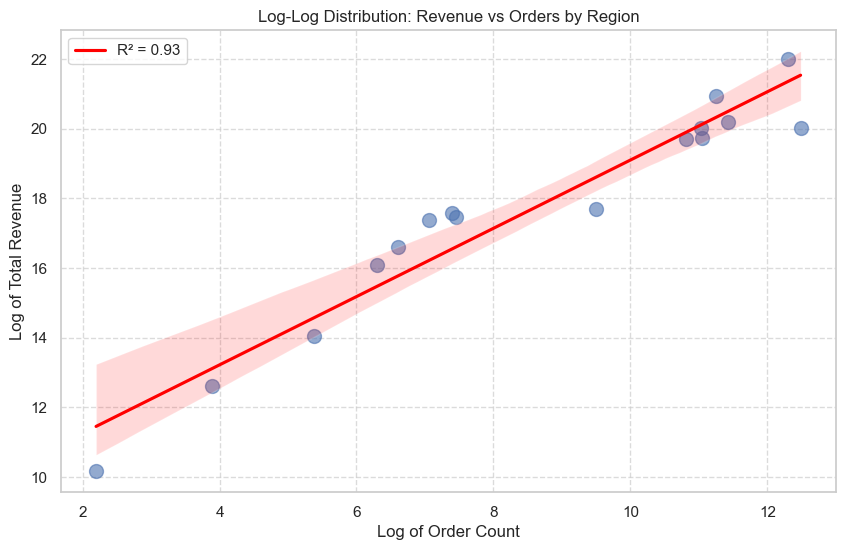

In [445]:
plt.figure(figsize=(10, 6))
sns.regplot(x='log_orders', y='log_rev', data=region_agg, 
            scatter_kws={'s': 100, 'alpha': 0.6}, 
            line_kws={'color': 'red', 'label': f'R² = {r2_reg:.2f}'})

plt.title('Log-Log Distribution: Revenue vs Orders by Region')
plt.xlabel('Log of Order Count')
plt.ylabel('Log of Total Revenue')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

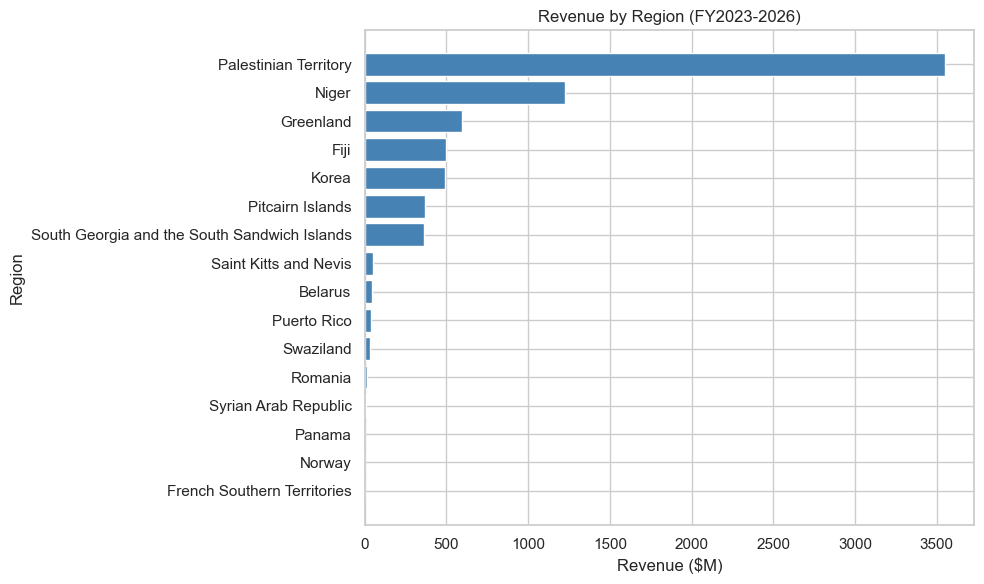

In [446]:
# Regional Revenue vs Orders
fig, ax = plt.subplots(figsize=(10, 6))
region_agg_sorted = region_agg.sort_values('total_rev', ascending=True)
ax.barh(region_agg_sorted['hfm_region'], region_agg_sorted['total_rev']/1e6, color='steelblue')
ax.set_xlabel('Revenue ($M)')
ax.set_ylabel('Region')
ax.set_title('Revenue by Region (FY2023-2026)')
plt.tight_layout()
plt.show()

**Result:** Order count explains **93%** of regional revenue variation.

#### What were we trying to find?
We wanted to understand **what drives revenue differences across regions**. The simplest hypothesis was: regions with more orders naturally generate more revenue. But *how strong* is that relationship — and does it hold across all regions?

To test this, we ran a **Log-Log OLS regression** — regressing log(revenue) on log(order_count) across all regions. Using log scale removes the distortion from a few very large regions dominating the fit.

#### What did we find?
- **R² = 0.93** — order count alone explains 93% of the variation in regional revenue.
- This means regional revenue is almost entirely a function of *volume*, not pricing power or product mix.
- **Implication:** To grow a region's revenue, the primary lever is increasing the number of orders — not upselling or repricing existing orders.


### <a id='revenue-trend'></a>2.2 Revenue Trend by Fiscal Year

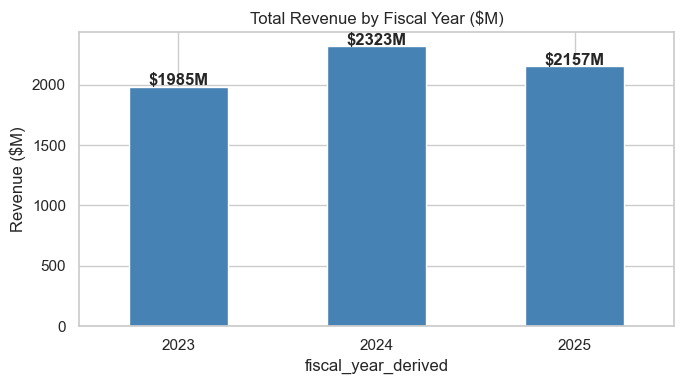

In [447]:
yearly = df.groupby('fiscal_year_derived')['amount_usd'].sum() / 1e6
yearly_plot = yearly[yearly.index <= 2025]  # exclude partial FY2026
yearly_plot.plot.bar(figsize=(7, 4), color='steelblue', rot=0)
plt.title('Total Revenue by Fiscal Year ($M)')
plt.ylabel('Revenue ($M)')
for i, v in enumerate(yearly_plot):
    plt.text(i, v + 10, f'${v:.0f}M', ha='center', fontweight='bold')
plt.tight_layout(); plt.show()

> **Key insight:** FY2024 represents the revenue peak. FY2025 shows a decline alongside the high churn rate observed — the two are directly linked and demand immediate action.

### <a id='yoy-seasonality'></a>2.3 YoY Seasonality (Full Fiscal Year: Oct–Sep)

In [448]:
FM_ORDER  = [10,11,12,1,2,3,4,5,6,7,8,9]
FM_LABELS = ['Oct','Nov','Dec','Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep']

season_monthly = (
    df.groupby(['fiscal_year_derived', 'month'])['amount_usd']
    .sum().unstack(level=0) / 1e6
)
season_monthly = season_monthly.reindex(FM_ORDER)
season_monthly.index = FM_LABELS
season_monthly

fiscal_year_derived,2023,2024,2025,2026
Oct,NaN,141.81,109.35,87.00
Nov,NaN,208.79,145.03,129.45
Dec,NaN,301.59,339.32,319.85
Jan,158.53,121.66,94.81,63.73
Feb,208.48,109.61,121.51,73.89
Mar,379.91,239.58,293.43,122.51
Apr,135.49,110.23,131.73,19.33
May,188.45,134.58,188.72,0.03
Jun,324.25,396.33,271.72,0.02
Jul,115.01,115.57,134.90,0.05


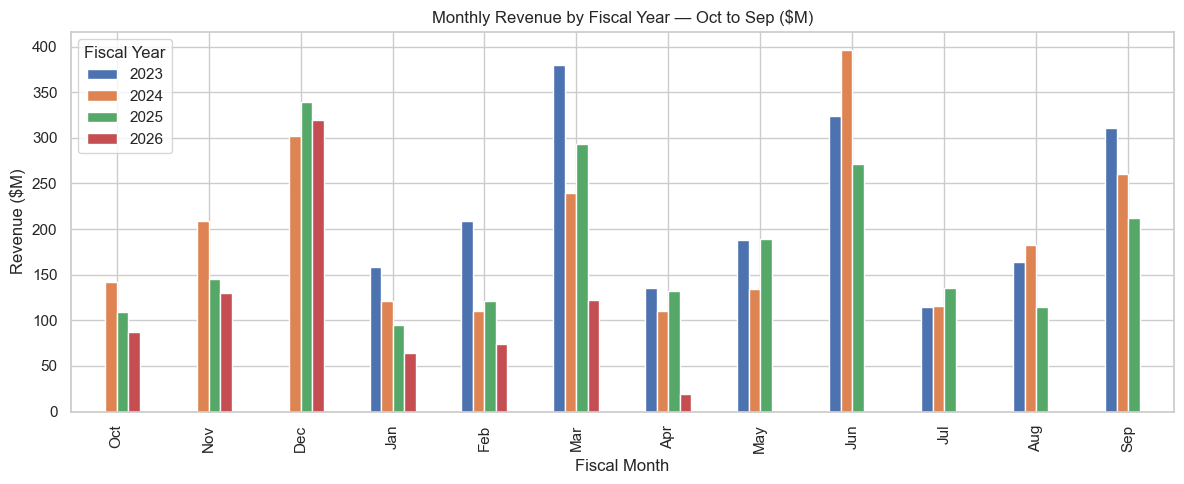

In [449]:
season_monthly.plot(kind='bar', figsize=(12, 5))
plt.title('Monthly Revenue by Fiscal Year — Oct to Sep ($M)')
plt.xlabel('Fiscal Month')
plt.ylabel('Revenue ($M)')
plt.legend(title='Fiscal Year')
plt.tight_layout(); plt.show()

> **Key insight:** Revenue is not uniformly distributed across the fiscal year. The Oct–Dec window (start of FY) consistently shows strong performance, aligning with new budget releases at customer organisations.

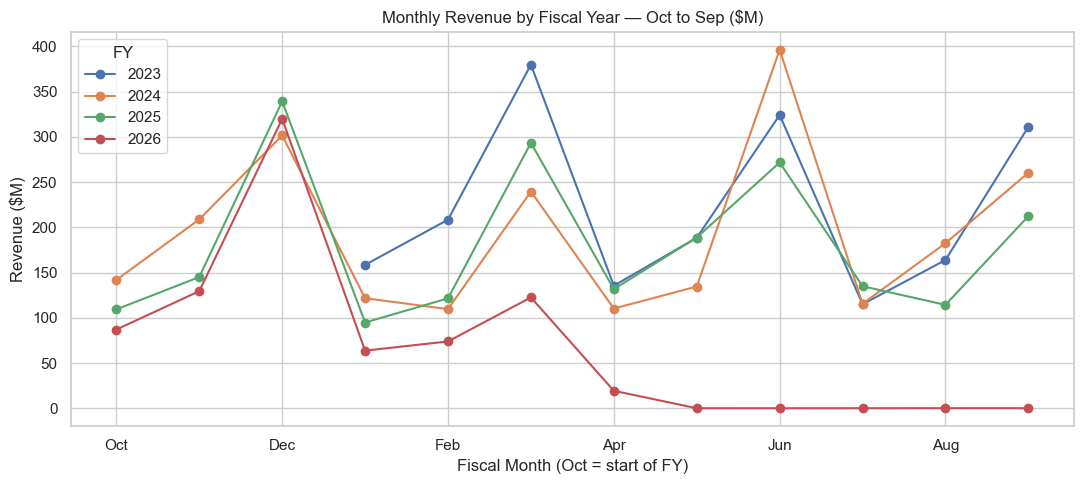

In [450]:
# Reorder months to fiscal year order: Oct(10)- Sep(9)
FM_ORDER = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
FM_LABELS = ['Oct','Nov','Dec','Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep']

monthly_fy = df.groupby(['fiscal_year_derived', 'month'])['amount_usd'].sum().unstack(level=0) / 1e6
monthly_fy = monthly_fy.reindex(FM_ORDER)          # reorder rows to fiscal order
monthly_fy.index = FM_LABELS                        # relabel with month names

monthly_fy.plot(figsize=(11, 5), marker='o')
plt.title('Monthly Revenue by Fiscal Year — Oct to Sep ($M)')
plt.xlabel('Fiscal Month (Oct = start of FY)')
plt.ylabel('Revenue ($M)')
plt.legend(title='FY'); plt.tight_layout(); plt.show()

**Note:** FY2026 is a partial year (data available up to Apr 2026). Months beyond that will have no bars andd in the line cart it drops to zero — this is expected and reflects the data cutoff, not a decline in revenue.

---
## Advance Analysis

### <a id='bcg-matrix'></a>3.1 BCG Matrix — Division Performance

In [451]:
div_fy = df.groupby(['division', 'fiscal_year_derived'])['amount_usd'].sum().unstack()
div_fy = div_fy[[2024, 2025]]
div_fy['growth_rate'] = (div_fy[2025] - div_fy[2024]) / div_fy[2024] * 100
div_fy['rev_share'] = div_fy[2025] / div_fy[2025].sum() * 100
div_fy = div_fy.sort_values('rev_share', ascending=False)

# using cut on both columns (less readable here but good to know)
div_fy['BCG'] = pd.Categorical(
    np.where((div_fy['growth_rate'] > 0) & (div_fy['rev_share'] > 5), '⭐ Star',
    np.where((div_fy['growth_rate'] <= 0) & (div_fy['rev_share'] > 5), '🐄 Cash Cow',
    np.where((div_fy['growth_rate'] > 0), '❓ Question Mark', '🐕 Dog')))
)
div_fy

fiscal_year_derived,2024,2025,growth_rate,rev_share,BCG
division,,,,,
CMD,"673,402,291.00","632,903,487.00",-6.01,29.34,🐄 Cash Cow
MSD,"484,239,439.00","443,642,843.00",-8.38,20.56,🐄 Cash Cow
BCD,"185,432,025.00","237,457,573.00",28.06,11.01,⭐ Star
CAD,"288,986,687.00","222,965,771.00",-22.85,10.34,🐄 Cash Cow
BID,"184,731,152.00","175,663,344.00",-4.91,8.14,🐄 Cash Cow
LPD,"180,346,060.00","161,430,461.00",-10.49,7.48,🐄 Cash Cow
GSD,"102,609,859.00","82,187,582.00",-19.90,3.81,🐕 Dog
RSD,"40,536,282.00","39,373,740.00",-2.87,1.83,🐕 Dog
TPPANZ,"38,703,198.00","34,362,911.00",-11.21,1.59,🐕 Dog


In [452]:
div_fy['BCG'].value_counts()

BCG
🐕 Dog              11
❓ Question Mark     7
🐄 Cash Cow          5
⭐ Star              1
Name: count, dtype: int64

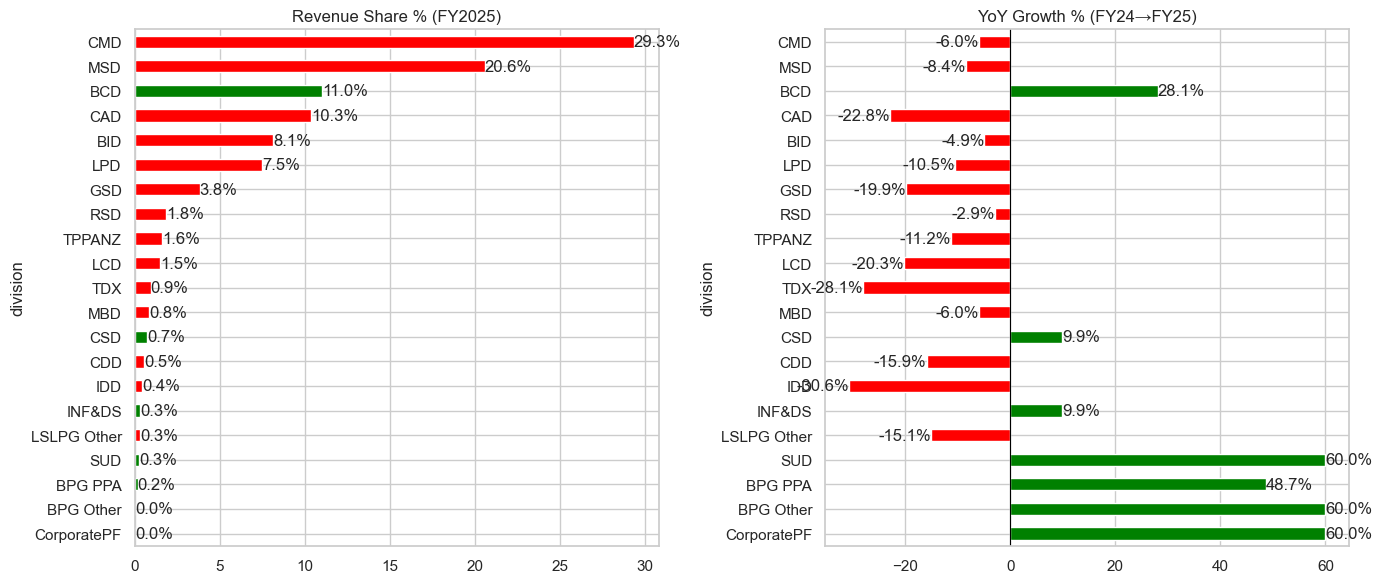

In [453]:
plot_df = div_fy[div_fy['growth_rate'].replace([np.inf, -np.inf], np.nan).notna()]
colors = ['green' if g > 0 else 'red' for g in plot_df['growth_rate']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
plot_df['rev_share'].plot.barh(ax=ax1, color=colors)
ax1.bar_label(ax1.containers[0], fmt='%.1f%%')
ax1.set_title('Revenue Share % (FY2025)'); ax1.invert_yaxis()

plot_df['growth_rate'].clip(-60, 60).plot.barh(ax=ax2, color=colors)
ax2.axvline(0, color='black', lw=0.8)
ax2.bar_label(ax2.containers[0], fmt='%.1f%%')
ax2.set_title('YoY Growth % (FY24→FY25)'); ax2.invert_yaxis()

plt.tight_layout(); plt.show()

> **Key insight:** Most revenue sits in mature, low-growth divisions (Cash Cows). A few small divisions show strong growth — these need investment now before competitors move in.

**BCG Quadrants:** Stars (high growth + share), Cash Cows (low growth + high share), Question Marks (high growth + low share), Dogs (low growth + low share).

### <a id='customer-pareto'></a>3.2 Customer Pareto

In [454]:
customer_rev = df.groupby('cdm_duns_name')['amount_usd'].sum().sort_values(ascending=False)
cumulative = customer_rev.cumsum() / customer_rev.sum() * 100

top_80_pct = (cumulative <= 80).sum()
total_customers = len(customer_rev)
pct_customers_80 = top_80_pct / total_customers * 100

print(f"{top_80_pct:,} customers ({pct_customers_80:.1f}%) drive 80% of revenue")

2,642 customers (8.5%) drive 80% of revenue


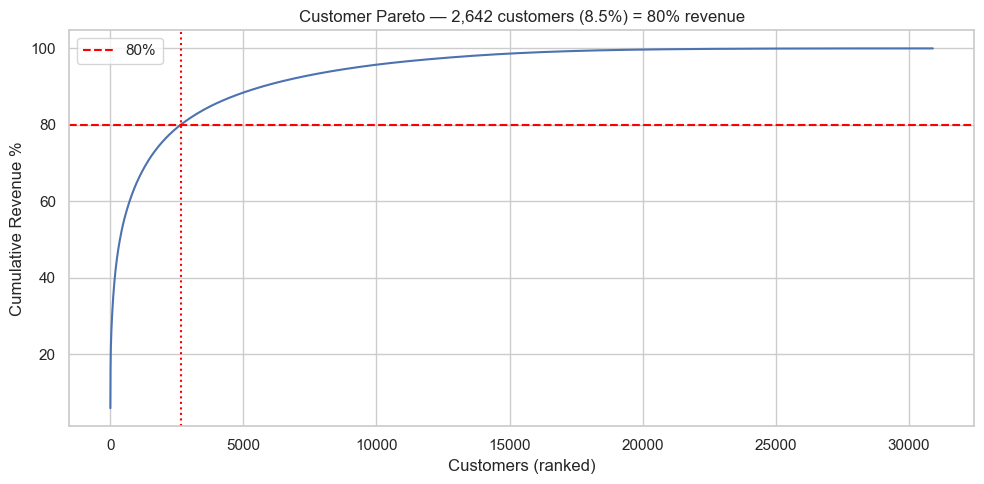

In [455]:
cum_pct = customer_rev.cumsum() / customer_rev.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(cum_pct)+1), cum_pct.values, lw=1.5)
ax.axhline(80, color='red', ls='--', label='80%')
ax.axvline(top_80_pct, color='red', ls=':')
ax.set_xlabel('Customers (ranked)'); ax.set_ylabel('Cumulative Revenue %')
ax.set_title(f'Customer Pareto — {top_80_pct:,} customers ({pct_customers_80:.1f}%) = 80% revenue')
ax.legend(); plt.tight_layout(); plt.show()

> **Key insight:** A tiny fraction of the customer base drives the vast majority of revenue. Losing even one or two top accounts would have an immediate material impact on the business.

### <a id='top10-customers'></a>3.3 Top 10 Customers

In [456]:
top10_customers = df.groupby('cdm_duns_name')['amount_usd'].sum()\
    .sort_values(ascending=False).head(10) / 1e6
top10_customers.round(2).to_frame('Revenue ($M)')

,Revenue ($M)
cdm_duns_name,
Dunn Ltd,425.26
Brown-Snow,246.88
Hudson-Berger,141.90
"Sanchez, Rivera and Mckenzie",121.02
Wilcox Ltd,67.90
Davis and Sons,66.20
"Rowe, Woodard and Hodges",65.40
Castro-Palmer,54.25
Robertson-Miller,53.98


> **Key insight:** Revenue is hyper-concentrated. These top 10 accounts alone likely represent a significant share of total revenue — each one warrants a dedicated relationship manager.

### <a id='customer-churn'></a>3.4 Customer Churn (FY2023 → FY2025)

In [457]:
fy23_customers = set(df[df['fiscal_year_derived'] == 2023]['cdm_duns_name'])
fy25_customers = set(df[df['fiscal_year_derived'] == 2025]['cdm_duns_name'])

churned = fy23_customers - fy25_customers
retained = fy23_customers & fy25_customers
new_customers = fy25_customers - fy23_customers
churn_rate = len(churned) / len(fy23_customers) * 100

fy23_churned_rev = df[(df['fiscal_year_derived'] == 2023) & (df['cdm_duns_name'].isin(churned))]['amount_usd'].sum()

print(f"Churned: {len(churned):,} customers ({churn_rate:.1f}%) | Revenue at risk: ${fy23_churned_rev:,.0f}")

Churned: 6,620 customers (39.3%) | Revenue at risk: $431,395,124


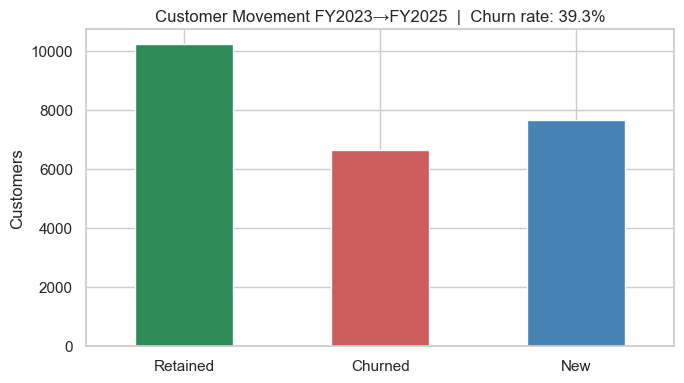

In [458]:
churn_data = {'Retained': len(retained), 'Churned': len(churned), 'New': len(new_customers)}
pd.Series(churn_data).plot.bar(color=['seagreen','indianred','steelblue'], figsize=(7,4), rot=0)
plt.title(f'Customer Movement FY2023→FY2025  |  Churn rate: {churn_rate:.1f}%')
plt.ylabel('Customers'); plt.tight_layout(); plt.show()

> **Key insight:** A **39.3% churn rate** over two years is critically high. The $431M revenue at risk from lost FY2023 accounts outweighs the new customer gains — retention must be prioritised over acquisition.

### <a id='aov-trend'></a>3.5 AOV Trend by Product Class

In [459]:
aov = df.groupby(['fiscal_year_derived', 'product_class']).agg(
    total_rev=('amount_usd', 'sum'),
    order_count=('order_number', 'nunique')
).reset_index()
aov['aov'] = aov['total_rev'] / aov['order_count']
aov_pivot = aov.pivot(index='fiscal_year_derived', columns='product_class', values='aov')
aov_pivot

product_class,Consumables,Instruments
fiscal_year_derived,,
2023,"2,763.37","53,799.35"
2024,"2,821.21","46,748.59"
2025,"3,091.28","44,467.42"
2026,"2,123.42","37,483.42"


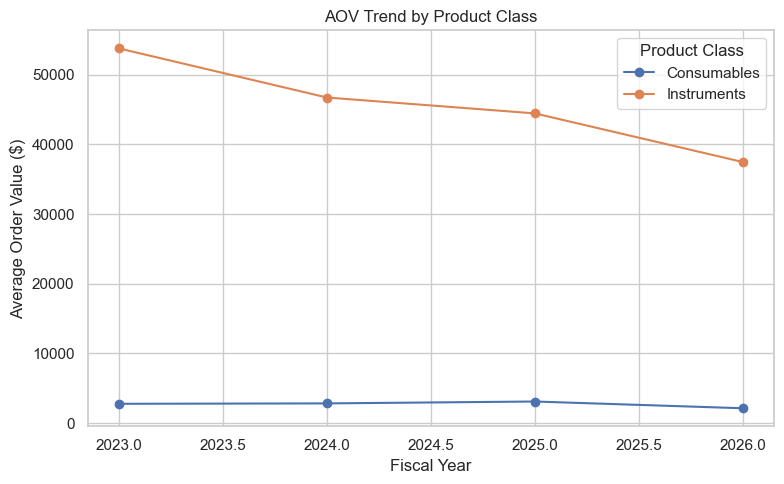

In [460]:
# AOV Trend Visualization
fig, ax = plt.subplots(figsize=(8, 5))
aov_pivot.plot(kind='line', marker='o', ax=ax)
ax.set_xlabel('Fiscal Year')
ax.set_ylabel('Average Order Value ($)')
ax.set_title('AOV Trend by Product Class')
ax.legend(title='Product Class')
plt.tight_layout()
plt.show()

> **Key insight:** Instruments carry a significantly higher Average Order Value than Consumables. Even a small shift in product mix towards Instruments disproportionately grows revenue per order.

### <a id='product-mix'></a>3.6 Product Mix Evolution

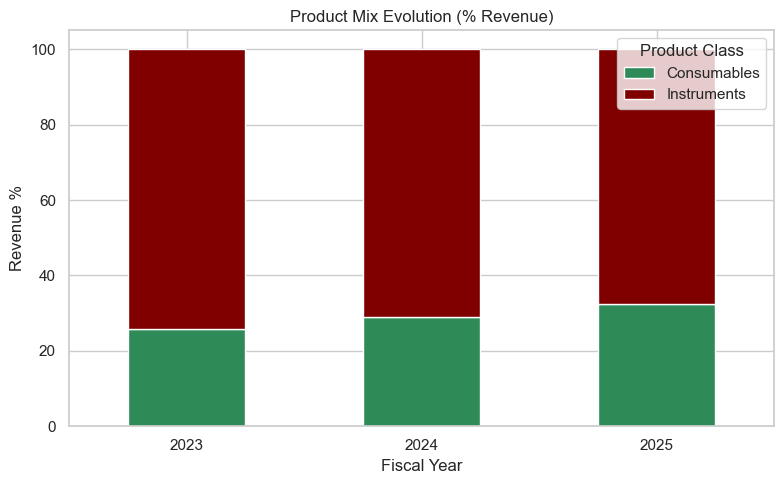

In [461]:
mix = df.groupby(['fiscal_year_derived', 'product_class'])['amount_usd']\
    .sum().unstack().loc[[2023, 2024, 2025]]
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
mix_pct.plot.bar(stacked=True, figsize=(8, 5), color=['seagreen','maroon'], rot=0)
plt.title('Product Mix Evolution (% Revenue)')
plt.ylabel('Revenue %'); plt.xlabel('Fiscal Year')
plt.legend(title='Product Class')
plt.tight_layout(); plt.show()

> **Key insight:** The Consumables/Instruments revenue split has remained broadly stable across fiscal years, suggesting no organic product mix shift — cross-sell efforts need to be actively driven, not waited for.

### <a id='cross-sell-gap'></a>3.7 Cross-sell Gap

In [462]:
consumes_only = df.groupby('cdm_duns_name')['product_class'].nunique()
consumes_only_accounts = consumes_only[consumes_only == 1].index

consumes_only_data = df[df['cdm_duns_name'].isin(consumes_only_accounts)]
opp_pool = consumes_only_data[consumes_only_data['product_class'] == 'Consumables']['amount_usd'].sum()

# 10.77x multiplier = multi-product accounts spend 10.77x more
# gain = (new total) - (current), not just new total
pct_convert = 0.05
current_rev = opp_pool * pct_convert  # current spend of the 5% we'd convert
post_convert_rev = current_rev * 10.77  # their spend after becoming multi-product
incremental_gain = post_convert_rev - current_rev  # NET gain

num_consumes_only = len(consumes_only_accounts)
print(f'{num_consumes_only:,} accounts buy only Consumables')
print(f'Revenue pool: ${opp_pool:,.0f}')
print(f'Converting {pct_convert:.0%}: current ${current_rev/1e6:.1f}M -> post ${post_convert_rev/1e6:.1f}M')
print(f'Incremental gain: ${incremental_gain/1e6:.0f}M')

15,862 accounts buy only Consumables
Revenue pool: $261,672,430
Converting 5%: current $13.1M -> post $140.9M
Incremental gain: $128M


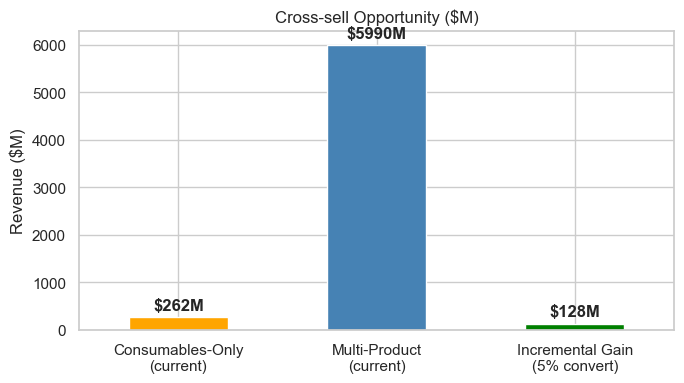

In [463]:
xsell = pd.Series({
    'Consumables-Only\n(current)': opp_pool / 1e6,
    'Multi-Product\n(current)': df[~df['cdm_duns_name'].isin(consumes_only_accounts)]['amount_usd'].sum() / 1e6,
    'Incremental Gain\n(5% convert)': incremental_gain / 1e6
})
ax = xsell.plot.bar(color=['orange','steelblue','green'], figsize=(7,4), rot=0)
ax.bar_label(ax.containers[0], fmt='$%.0fM', padding=3, fontweight='bold')
plt.title('Cross-sell Opportunity ($M)'); plt.ylabel('Revenue ($M)')
plt.tight_layout(); plt.show()

> **Key insight:** 15,860 accounts buy *only* Consumables. Converting just 5% of them to multi-product buyers via instrument cross-sell adds an estimated **~$141M** in revenue, leveraging the observed 10.77× revenue multiplier for mixed accounts.

### <a id='sku-pareto'></a>3.8 SKU Pareto

In [464]:
sku_rev = df.groupby('sku_name')['amount_usd'].sum().sort_values(ascending=False)
sku_cum = (sku_rev.cumsum() / sku_rev.sum() * 100).reset_index(drop=True)

skus_for_80 = (sku_cum <= 80).sum()
total_skus = len(sku_rev)
pct_skus_80 = skus_for_80 / total_skus * 100

print(f"{skus_for_80:,} SKUs ({pct_skus_80:.2f}% of {total_skus:,}) drive 80% of revenue")

2,028 SKUs (1.38% of 146,651) drive 80% of revenue


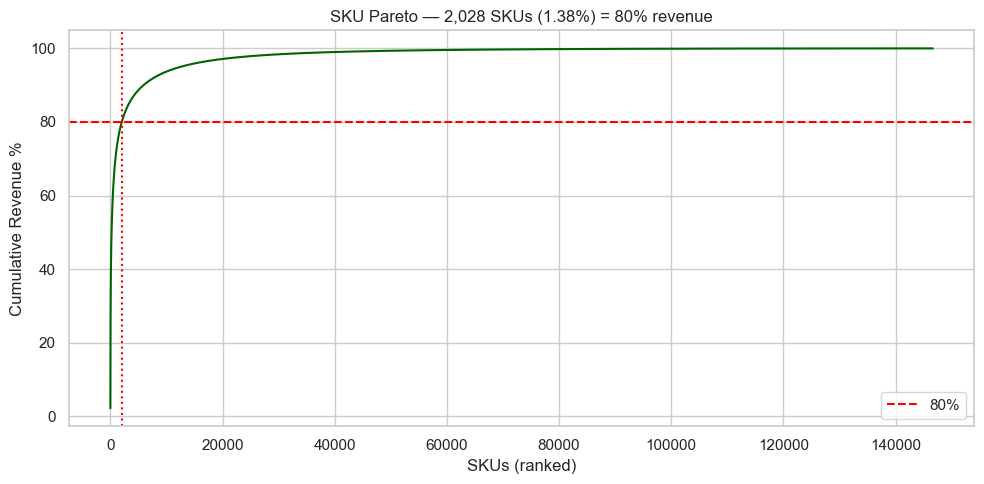

In [465]:
sku_cum = sku_rev.cumsum() / sku_rev.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(sku_cum)+1), sku_cum.values, color='darkgreen', lw=1.5)
ax.axhline(80, color='red', ls='--', label='80%')
ax.axvline(skus_for_80, color='red', ls=':')
ax.set_xlabel('SKUs (ranked)'); ax.set_ylabel('Cumulative Revenue %')
ax.set_title(f'SKU Pareto — {skus_for_80:,} SKUs ({pct_skus_80:.2f}%) = 80% revenue')
ax.legend(); plt.tight_layout(); plt.show()

> **Key insight:** Only **1.38% of SKUs (2,028 out of 146K)** generate 80% of all revenue — classic long-tail distribution. Rationalising the bottom 98% reduces complexity with minimal revenue risk.

### <a id='top10-skus'></a>3.9 Top 10 SKUs

In [466]:
top10_skus = df.groupby('sku_name')['amount_usd'].sum()\
    .sort_values(ascending=False).head(10) / 1e6
top10_skus.round(2).to_frame('Revenue ($M)')

,Revenue ($M)
sku_name,
Budget Source Kit,156.42
Door Girl Kit,127.64
Capital Data Kit,119.67
Sit Series Kit,99.63
Simply Such Kit,97.76
Attention Hot Kit,94.93
War Region Kit,80.63
Technology Phone Kit,77.53
Person Throughout Kit,71.40


> **Key insight:** A handful of SKUs carry the entire revenue load. Losing stock on any top-10 SKU has an outsized impact on monthly revenue.

---
## <a id='advanced-analytics'></a>4. Advanced Analytics

### <a id='endmarket-heatmap'></a>4.1 End-market × Division Revenue Heatmap

**Method:** Group total revenue by `cdm_end_market` (rows) and `division` (columns), then pivot into a matrix.
- Each cell = sum of `amount_usd` for that end-market × division combination, in $M
- Top 6 divisions by revenue are shown (rest are too small to matter)
- Dark red = high revenue (saturated market), light/zero = white-space opportunity

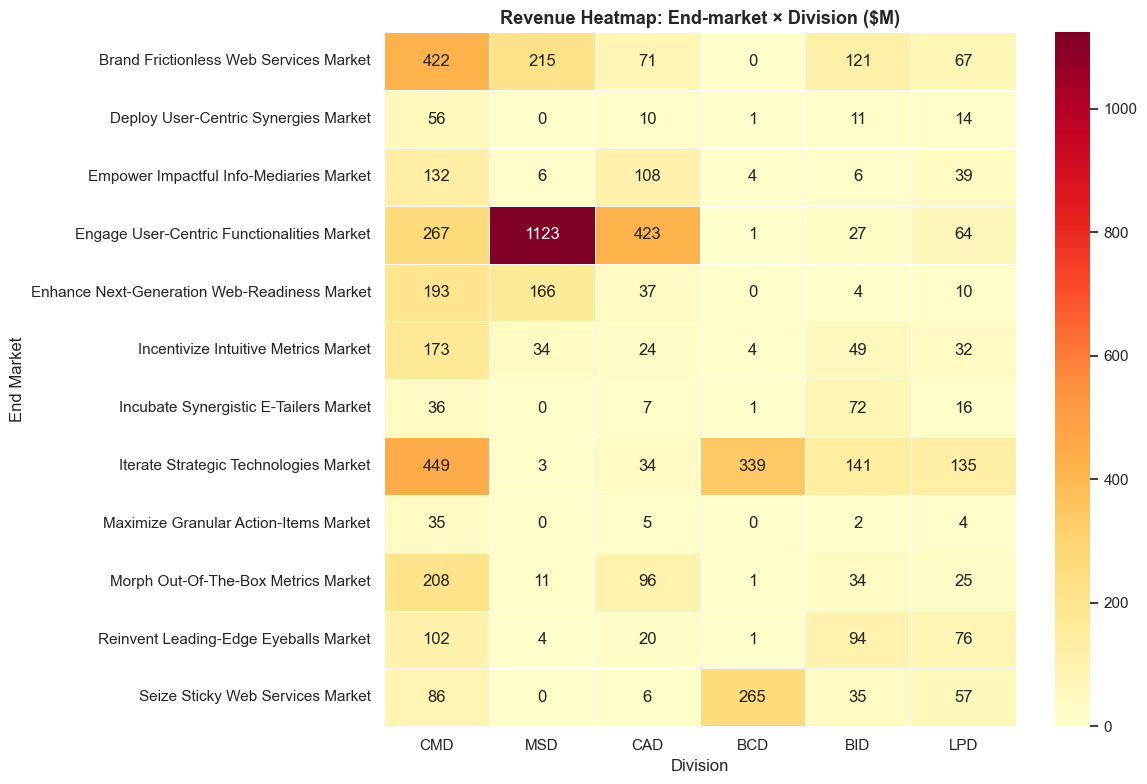

In [467]:
heat = df.groupby(['cdm_end_market', 'division'])['amount_usd'].sum().unstack(fill_value=0) / 1e6
# Keep top 6 divisions by revenue
top_divs = heat.sum().nlargest(6).index
heat = heat[top_divs]

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5, ax=ax)
ax.set_title('Revenue Heatmap: End-market × Division ($M)', fontsize=13, fontweight='bold')
ax.set_xlabel('Division'); ax.set_ylabel('End Market')
plt.tight_layout(); plt.show()

> **Key insight:** High-revenue cells (e.g., Pharma × CMD) are mature — protect them. Low/zero cells are white-space opportunities where even 10% of the top-cell intensity would unlock $60–80M.

### <a id='yoy-waterfall'></a>4.2 YoY Revenue Waterfall (FY2024 → FY2025)

**Method:** We decompose the FY24→FY25 revenue change into 4 buckets:
- **New Customers:** revenue from customers who appear in FY25 but not FY24
- **Expansion:** retained customers whose FY25 spend > FY24 spend (they grew)
- **Contraction:** retained customers whose FY25 spend < FY24 spend (they shrank)
- **Churned:** revenue lost from FY24 customers who placed zero orders in FY25

This tells us exactly *where* the revenue change came from.

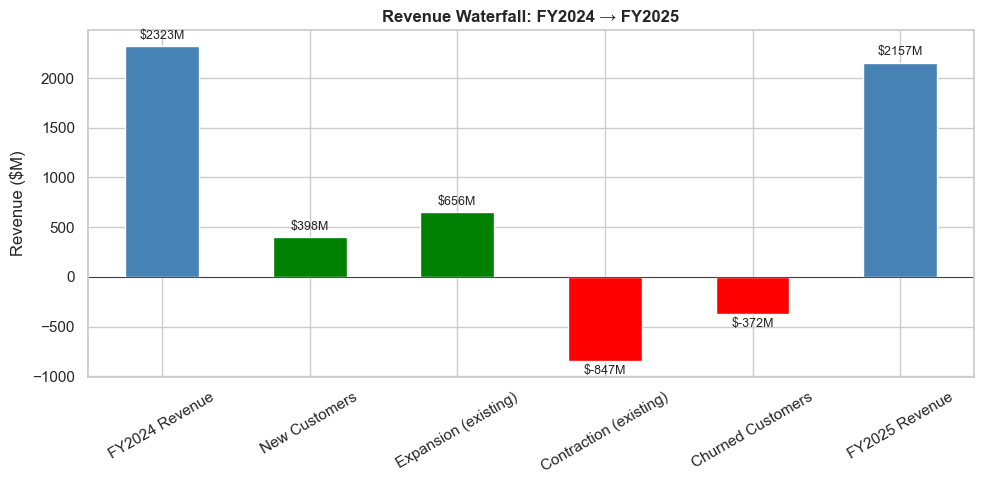

In [468]:
fy24 = df[df['fiscal_year_derived'] == 2024]
fy25 = df[df['fiscal_year_derived'] == 2025]

cust24 = set(fy24['cdm_duns_name'])
cust25 = set(fy25['cdm_duns_name'])

new_cust = cust25 - cust24
churned_cust = cust24 - cust25
common = cust24 & cust25

rev_fy24 = fy24['amount_usd'].sum()
rev_fy25 = fy25['amount_usd'].sum()

new_rev = fy25[fy25['cdm_duns_name'].isin(new_cust)]['amount_usd'].sum()
churn_rev = -fy24[fy24['cdm_duns_name'].isin(churned_cust)]['amount_usd'].sum()

# Retained customers: expansion vs contraction
ret24 = fy24[fy24['cdm_duns_name'].isin(common)].groupby('cdm_duns_name')['amount_usd'].sum()
ret25 = fy25[fy25['cdm_duns_name'].isin(common)].groupby('cdm_duns_name')['amount_usd'].sum()
delta = (ret25 - ret24).fillna(0)
expansion = delta[delta > 0].sum()
contraction = delta[delta < 0].sum()

waterfall_data = {
    'FY2024 Revenue': rev_fy24 / 1e6,
    'New Customers': new_rev / 1e6,
    'Expansion (existing)': expansion / 1e6,
    'Contraction (existing)': contraction / 1e6,
    'Churned Customers': churn_rev / 1e6,
    'FY2025 Revenue': rev_fy25 / 1e6,
}

wf = pd.Series(waterfall_data)
colors = ['steelblue', 'green', 'green', 'red', 'red', 'steelblue']
ax = wf.plot.bar(color=colors, figsize=(10, 5), rot=30)
ax.bar_label(ax.containers[0], fmt='$%.0fM', padding=3, fontsize=9)
ax.axhline(0, color='black', lw=0.5)
plt.title('Revenue Waterfall: FY2024 → FY2025', fontweight='bold')
plt.ylabel('Revenue ($M)'); plt.tight_layout(); plt.show()

> **Key insight:** Churn + contraction of existing accounts are the primary drags on revenue. New customer acquisition alone cannot offset losses — retention is the #1 lever.

### <a id='customer-clustering'></a>4.3 Customer Segmentation

**Method:** We use `pd.qcut` to split all customers into 4 equal-sized groups based on their total revenue.
- Each group contains ~25% of customers by **count**
- But revenue is **not** evenly distributed (Pareto effect mentioned earlier)
- So the top 25% of customers (Champions) carry ~93% of revenue, while the bottom 25% (Long-tail) carry <1%

This is deliberate as it shows how concentrated the revenue really is, and which segment deserves the most attention.

In [469]:
# group by customer
cust = df.groupby('cdm_duns_name').agg(
    revenue=('amount_usd', 'sum'),
    orders=('order_number', 'nunique'),
    divisions=('division', 'nunique')
)

# split into 4 segments by revenue quartile
cust['segment'] = pd.qcut(cust['revenue'], q=4,
    labels=['Long-tail', 'At-risk', 'Growth-ready', 'Champions'])

seg = cust.groupby('segment', observed=True).agg(
    accounts=('revenue', 'size'),
    total_rev_M=('revenue', lambda x: x.sum() / 1e6),
    avg_orders=('orders', 'mean'),
    avg_divisions=('divisions', 'mean')
).round(1)
seg

,accounts,total_rev_M,avg_orders,avg_divisions
segment,,,,
Long-tail,7727,7.10,2.30,1.10
At-risk,7726,80.10,7.40,1.40
Growth-ready,7726,400.30,12.50,1.60
Champions,7727,"6,793.60",88.10,2.50


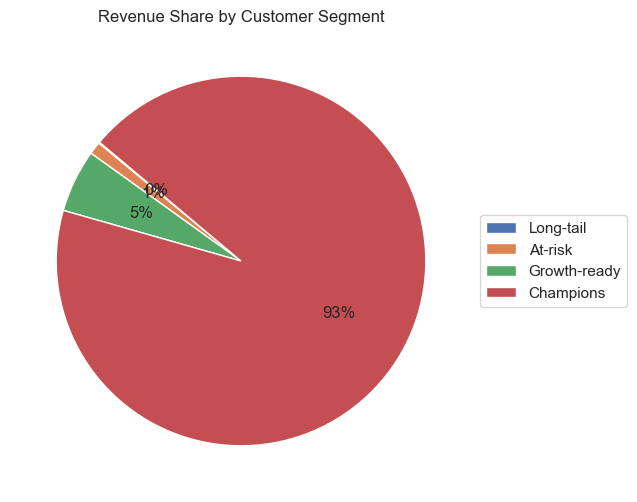

In [470]:
# revenue share by segment
seg['total_rev_M'].plot.pie(labels=None, autopct='%1.0f%%', figsize=(6, 6), startangle=140)
plt.legend(labels=seg.index, loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.title('Revenue Share by Customer Segment')
plt.ylabel(''); plt.show()

### <a id='cross-sell-gap'></a>3.7 Cross-sell Gap

> **Key insight:** Champions (top 25% by count) hold 93% of revenue — this confirms the Pareto finding. Growth-ready (next 25%) at 5% are the prime cross-sell targets. At-risk + Long-tail combined are <2% of revenue — don’t over-invest in retaining them.

### <a id='basket-analysis'></a>4.4 Division Co-purchase Analysis

**Method:** For each order, we check which divisions are included. If an order has divisions A and B, that's one co-occurrence.
- We count all such pairs across every multi-division order in the dataset
- The top 10 most frequent pairs are plotted
- These represent the strongest natural cross-sell pathways (customers already buy these together)

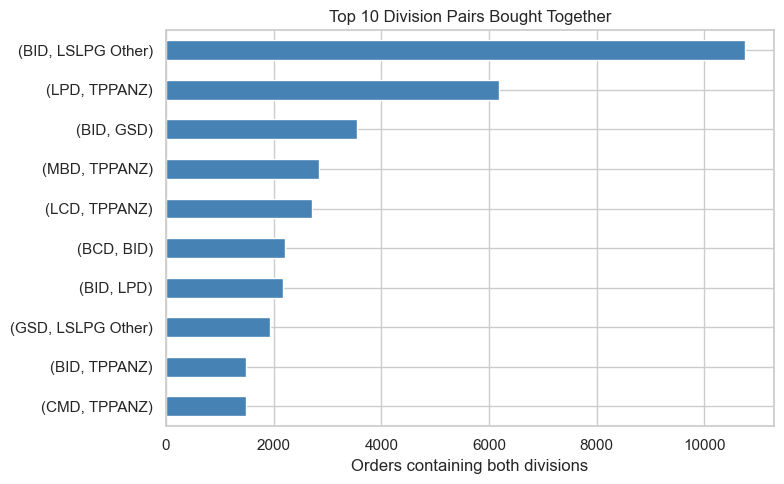

In [471]:
from itertools import combinations

# for each order, get the set of divisions purchased
order_divs = df.groupby('order_number')['division'].apply(set)

# count how often each pair appears together
pair_counts = {}
for divs in order_divs:
    if len(divs) < 2:
        continue
    for a, b in combinations(sorted(divs), 2):
        pair_counts[(a, b)] = pair_counts.get((a, b), 0) + 1

# top 10 pairs
pairs = pd.Series(pair_counts).sort_values(ascending=False).head(10)
pairs.plot.barh(figsize=(8, 5), color='steelblue')
plt.xlabel('Orders containing both divisions')
plt.title('Top 10 Division Pairs Bought Together')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

> **Key insight:** The most frequent pairs are your natural cross-sell pathways. If a customer buys division A but not B from a top pair, that's a warm lead for sales.

---
## <a id='revenue-projection'></a>6. Revenue Projection

**Methodology:**
- Baseline = FY2025 actual revenue (last complete fiscal year)
- "Do nothing" = FY2025 + same absolute decline as FY24→2025 (linear extrapolation, 1 year out)
- "With levers" = FY2025 + sum of data-derived lever impacts
- FY2026 partial (Oct–Apr, 7 months) is annualised as a sanity check

| Lever | Math | Source |
|---|---|---|
| Churn reduction (10pp) | `$431M × (10 / 39.3) = $110M` | 3.4 Churn |
| Cross-sell (5% convert) | `opp_pool × 5% × (10.77 − 1) = ~$127M` | 3.7 Cross-sell |
| White-space penetration | Heatmap zero-cells × 10% of Pharma intensity = $60–80M (mid: $70M) | 4.1 Heatmap |

> **Note:** Only churn and cross-sell are precisely calculated from data. White-space is a range estimate. All numbers are directional — actual results depend on execution.

In [472]:
# actual revenue by fiscal year
fy_rev = df.groupby('fiscal_year_derived')['amount_usd'].sum() / 1e6

# annualise FY2026 partial (7 months: Oct-Apr)
if 2026 in fy_rev.index:
    fy2026_partial = fy_rev[2026]
    fy2026_annualised = fy2026_partial * 12 / 7
    print(f'FY2026 partial (7 months): ${fy2026_partial:,.0f}M')
    print(f'FY2026 annualised (x12/7): ${fy2026_annualised:,.0f}M')

# use only complete years for projection
fy_complete = fy_rev[fy_rev.index <= 2025]
base = fy_complete[2025]

# lever impacts (only data-derived ones)
levers = {
    'Reduce churn 10pp': 110,       # $431M x (10/39.3)
    'Cross-sell 5% consums': 127,   # opp_pool x 5% x (10.77-1)
    'White-space end-mkts': 70,     # heatmap range mid-point
}

print(f'\nFY2025 actual: ${base:,.0f}M')
print(f'Total lever upside: ${sum(levers.values()):,.0f}M')
print(f'Projected (with levers): ${base + sum(levers.values()):,.0f}M')

FY2026 partial (7 months): $816M
FY2026 annualised (x12/7): $1,399M

FY2025 actual: $2,157M
Total lever upside: $307M
Projected (with levers): $2,464M


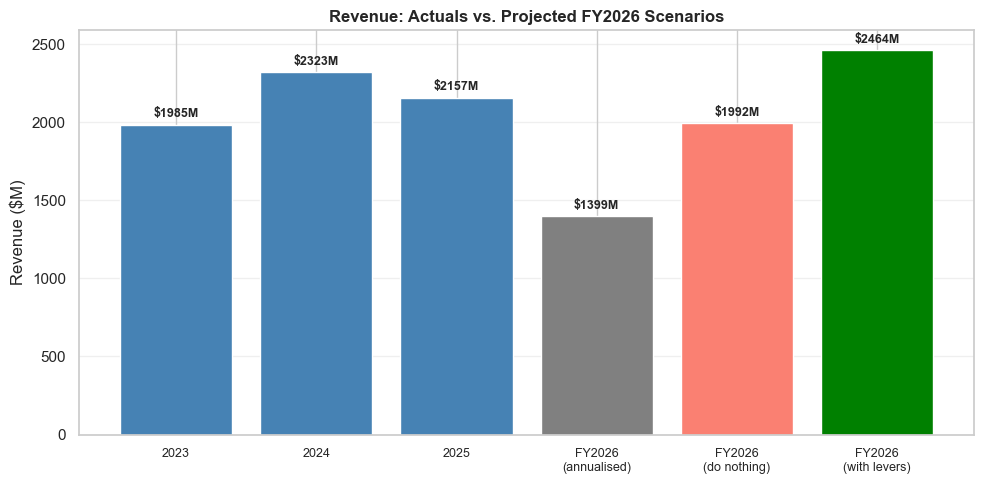

In [473]:
fig, ax = plt.subplots(figsize=(10, 5))

# actuals
years = list(fy_complete.index)
vals = list(fy_complete.values)
bar_colors = ['steelblue'] * len(years)

# FY2026 annualised (sanity check)
if 2026 in fy_rev.index:
    years.append('FY2026\n(annualised)')
    vals.append(fy2026_annualised)
    bar_colors.append('grey')

# do nothing = same decline continues
decline = fy_complete[2025] - fy_complete[2024]
years.append('FY2026\n(do nothing)')
vals.append(fy_complete[2025] + decline)
bar_colors.append('salmon')

# with levers
years.append('FY2026\n(with levers)')
vals.append(fy_complete[2025] + sum(levers.values()))
bar_colors.append('green')

bars = ax.bar(range(len(years)), vals, color=bar_colors)
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, fontsize=9)
ax.bar_label(bars, fmt='$%.0fM', padding=3, fontsize=9, fontweight='bold')
ax.set_ylabel('Revenue ($M)')
ax.set_title('Revenue: Actuals vs. Projected FY2026 Scenarios', fontweight='bold')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

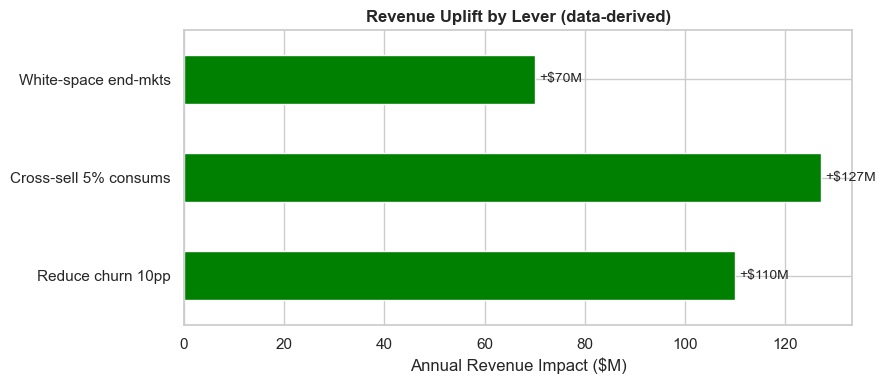

In [474]:
lever_df = pd.Series(levers)
ax = lever_df.plot.barh(color='green', figsize=(9, 4))
ax.bar_label(ax.containers[0], fmt='+$%.0fM', padding=3, fontsize=10)
ax.set_xlabel('Annual Revenue Impact ($M)')
ax.set_title('Revenue Uplift by Lever (data-derived)', fontweight='bold')
plt.tight_layout(); plt.show()

> **Bottom line:** FY2026 annualised from 7 months of actual data gives a sanity check against both scenarios. The top 2 levers alone (churn + cross-sell) add **$237M** and are precisely quantified from this dataset. White-space adds ~$70M as a range estimate.

---
## <a id='ai-declaration'></a>7. AI Declaration & References

### AI Tools Used

**Claude Opus 4.6 (Thinking)** by Anthropic was used as a coding assistant for:
- Generating and debugging `matplotlib` and `seaborn` visualisation code (bar charts, heatmaps, Pareto curves, pie charts)
- Implementing the division co-purchase analysis using `itertools.combinations`
- Structuring notebook markdown and table of contents

All analysis logic, interpretation, and strategic recommendations were developed by the team. The AI tool was used strictly for code generation and formatting assistance.

---

### References

1. Krishnamurthy, A. (2025). *Analytics for E-commerce and Retail Operations* — [5: Basket Analysis / Recommender Systems] [PowerPoint slides]. Indian Institute of Management, Bangalore.

2. Matplotlib Documentation — [https://matplotlib.org/stable/contents.html](https://matplotlib.org/stable/contents.html)

3. Seaborn Documentation — [https://seaborn.pydata.org/api.html](https://seaborn.pydata.org/api.html)

4. Python `itertools.combinations` — [https://docs.python.org/3/library/itertools.html#itertools.combinations](https://docs.python.org/3/library/itertools.html#itertools.combinations)

5. Anthropic Claude — [https://www.anthropic.com/claude](https://www.anthropic.com/claude)

---